# 03 · Competição: Modelo A (Ridge) × Modelo B (Random Forest)

- **Mesmas features** (eleitas no notebook 02), **mesmo treino**, **mesmas seeds**.
- Cada modelo é um `Pipeline` (atributos derivados → seleção → imputação → padronização → regressor). O pré-processamento é serializado **junto** ao modelo.
- **Validação cruzada em 5 folds por traço**. A votação e o pré-processamento são refeitos só com o treino de cada fold.
- A **decisão** usa o **MAE na validação fixa**, que não participou da seleção de features nem do treino.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
import joblib
from src.ingestao import carregar_treino_acumulado, carregar_validacao
from src.modelagem import treinar_e_avaliar, baseline_mae, preparar_folds
from src.particionamento import validar_separacao
from src.utils import DIR_CICLO

ctx = carregar_contexto()
ev = dir_evidencias(ctx["cycle_id"])
treino = carregar_treino_acumulado(cfg)
validacao = carregar_validacao(cfg)
validar_separacao(treino=treino, validacao=validacao)
folds = preparar_folds(treino, cfg)
features = ctx["features_eleitas"]
alvo = cfg["dados"]["alvo"]
mae_base = baseline_mae(treino[alvo], validacao[alvo])
print("Features:", features, "| treino:", len(treino), "| validação fixa:", len(validacao))
print(f"Baseline (prever a média) – MAE validação: {mae_base:.3f}")

Features: ['idade', 'aglomerante_total', 'log_idade', 'relacao_agua_aglomerante', 'cimento'] | treino: 342 | validação fixa: 131
Baseline (prever a média) – MAE validação: 14.235


In [3]:
mlflow = configurar_mlflow(cfg)
resultados = {}
for chave in ["A", "B"]:
    spec = cfg["modelos"][chave]
    modelo, met = treinar_e_avaliar(spec["algoritmo"], spec["params"], features, treino, validacao, cfg, folds)
    arq = DIR_CICLO / f"candidato_{chave}.joblib"
    joblib.dump(modelo, arq)
    with mlflow.start_run(run_name=f"modelo{chave}_{spec['algoritmo']}_{ctx['cycle_id']}") as run:
        mlflow.set_tags({"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"],
                         "etapa": "treino", "candidato": chave, "algoritmo": spec["algoritmo"]})
        mlflow.log_params({**{f"hp_{k}": v for k, v in spec["params"].items()}, "algoritmo": spec["algoritmo"],
                           "seed": cfg["projeto"]["seed"], "features": ",".join(features), "n_features": len(features),
                           "n_treino": len(treino), "cv_folds": cfg["avaliacao"]["cv_folds"]})
        mlflow.log_metrics({**met, "baseline_val_mae": mae_base})
        mlflow.sklearn.log_model(modelo, name="modelo", code_paths=[str(RAIZ / "src")],
                                 skops_trusted_types=["numpy.dtype", "src.preprocessamento.criar_atributos", "sklearn.tree._tree.Tree"])
    resultados[chave] = {"algoritmo": spec["algoritmo"], "run_id": run.info.run_id, "arquivo": str(arq), **met}
    print(f"Modelo {chave} ({spec['algoritmo']}): MAE val = {met['val_mae']:.3f} | CV MAE = {met['cv_mae_media']:.3f} ± {met['cv_mae_desvio']:.3f} | R² val = {met['val_r2']:.3f}")

comp = pd.DataFrame(resultados).T[["algoritmo", "val_mae", "val_rmse", "val_r2", "cv_mae_media", "cv_mae_desvio", "run_id"]]
display(comp)
comp.to_csv(ev / "comparacao_modelos.csv")

Modelo A (ridge): MAE val = 6.561 | CV MAE = 5.711 ± 0.407 | R² val = 0.717


Modelo B (random_forest): MAE val = 6.209 | CV MAE = 4.732 ± 0.346 | R² val = 0.782


,algoritmo,val_mae,val_rmse,val_r2,cv_mae_media,cv_mae_desvio,run_id
A,ridge,6.56113,9.210212,0.717277,5.711057,0.406555,04574853d12b46c6a8e2ecbc38d31978
B,random_forest,6.208989,8.091079,0.78181,4.732138,0.345812,76cea35c1358426abb21eaf95061d355


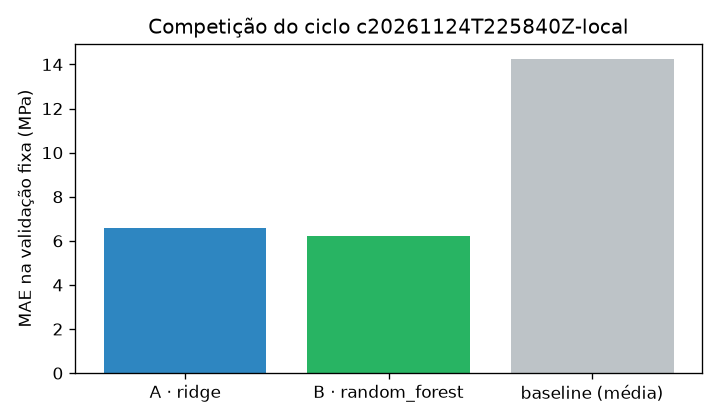

{'cycle_id': 'c20261124T225840Z-local',
 'data_version': 'v1-f78d2fdb',
 'lote': 'lote_01.csv',
 'n_treino': 342,
 'gatilho': 'local',
 'etl': {'linhas_recebidas': 342,
  'removidas_alvo_ausente': 0,
  'removidas_traco_incompleto': 0,
  'removidas_fora_da_faixa': 0,
  'removidas_duplicadas_no_lote': 0,
  'removidas_ja_incorporadas': 0,
  'ausentes_para_imputacao': 0,
  'linhas_aceitas': 342},
 'drift_resumo': None,
 'drift_alerta': False,
 'run_etl': 'f09e398d1a8940c68847bd9666c74572',
 'features_eleitas': ['idade',
  'aglomerante_total',
  'log_idade',
  'relacao_agua_aglomerante',
  'cimento'],
 'criterio_votacao': '>= 2 votos',
 'selecao_por_metodo': {'selectkbest_f_regression': ['aglomerante_total',
   'cimento',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante'],
  'importancia_random_forest': ['aglomerante_total',
   'idade',
   'log_idade',
   'relacao_agua_aglomerante',
   'relacao_agua_cimento'],
  'rfe_ridge': ['aglomerante_total', 'agua', 'cimento', 'idade', 'log_ida

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f"A · {resultados['A']['algoritmo']}", f"B · {resultados['B']['algoritmo']}", "baseline (média)"],
       [resultados["A"]["val_mae"], resultados["B"]["val_mae"], mae_base], color=["#2e86c1", "#28b463", "#bdc3c7"])
ax.set_ylabel("MAE na validação fixa (MPa)"); ax.set_title(f"Competição do ciclo {ctx['cycle_id']}")
fig.tight_layout(); fig.savefig(ev / "comparacao_modelos.png", dpi=120); plt.close(fig)
display(Image(str(ev / "comparacao_modelos.png")))
salvar_contexto({"resultados": resultados, "baseline_val_mae": mae_base})